# Plotting with Matplotlib and Seaborn

Plots help you explore data and communicate evidence. They can also hide uncertainty, exaggerate differences, and create extremely colorful confusion.

## 1. Imports, data, and a consistent theme

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


candidate_paths = [
  parent / "data" / "aai_student_data.csv"
  for parent in (Path.cwd(), *Path.cwd().parents)
]
data_path = next((path for path in candidate_paths if path.exists()), None)
if data_path is None:
  raise FileNotFoundError("Could not find the synthetic AAI dataset.")

students = pd.read_csv(data_path, parse_dates=["enrollment_date"])
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
students.head()

,student_id,study_program,python_experience,weekly_study_hours,attendance_percent,assignments_completed,coffee_cups_per_week,exam_score,passed,tutorial_group,enrollment_date
0,AAI001,Business Administration,Intermediate,6.0,90,8,1,70.2,True,T1,2026-04-07
1,AAI002,Business Administration,Advanced,11.3,100,8,10,80.8,True,T2,2026-04-08
2,AAI003,Philosophy,Basic,9.4,71,9,1,70.5,True,T3,2026-04-09
3,AAI004,Mathematics,Intermediate,7.6,79,8,14,60.7,True,T1,2026-04-10
4,AAI005,Computer Science,Basic,5.0,59,10,0,47.2,False,T2,2026-04-11


## 2. Figure and axes

A **Figure** is the complete canvas. An **Axes** is one plotting area. The object-oriented Matplotlib API (`fig, ax = plt.subplots()`) makes labels, layouts, and multiple panels explicit.

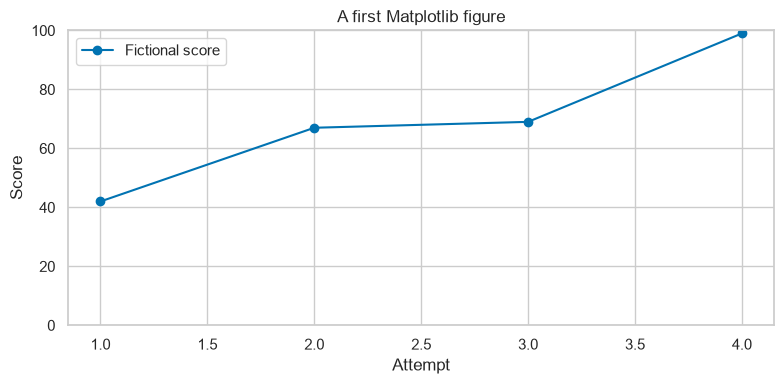

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([1, 2, 3, 4], [42, 67, 69, 99], marker="o", label="Fictional score")
ax.set(
  title="A first Matplotlib figure",
  xlabel="Attempt",
  ylabel="Score",
  ylim=(0, 100),
)
ax.legend()
fig.tight_layout()
plt.show()

### Solution: annotate a plot

Add a title, axis labels, and a text annotation for the point at `(3, 69)`. The starter plot already runs.

**Explanation:** `ax.set()` adds the descriptive labels in one call. `annotate()` points from explanatory text to the selected data coordinate using an arrow.

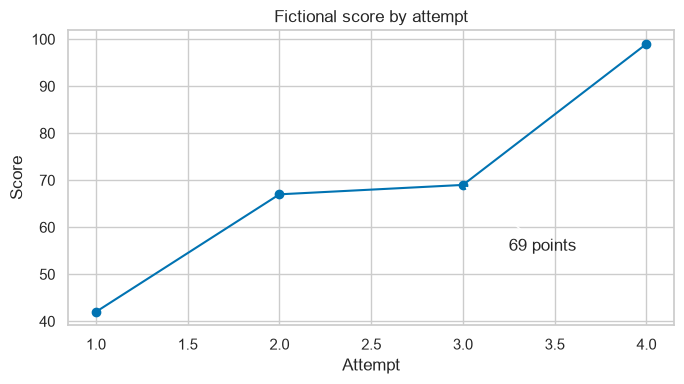

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([1, 2, 3, 4], [42, 67, 69, 99], marker="o")

### --- Start Solution --- ###
ax.set(title="Fictional score by attempt", xlabel="Attempt", ylabel="Score")
ax.annotate(
  "69 points",
  xy=(3, 69),
  xytext=(3.25, 55),
  arrowprops={"arrowstyle": "->"},
)
### --- End Solution --- ###

fig.tight_layout()
plt.show()

## 3. Common Matplotlib plots

Choose the plot based on the question and variable types, not because one chart happens to look dramatic.

### Line plots: change over an ordered dimension

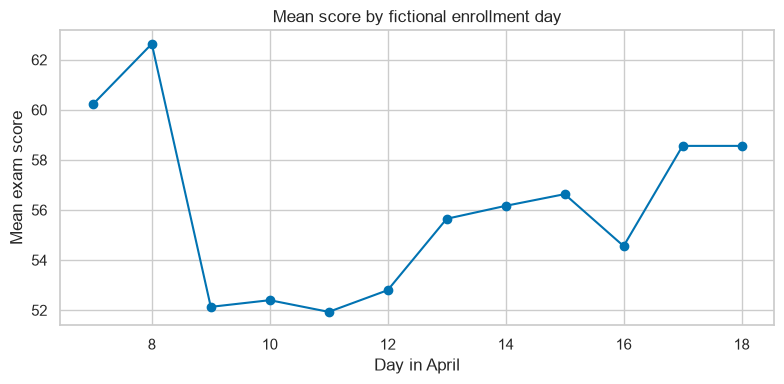

In [4]:
weekly_average = (
  students
  .assign(enrollment_day=lambda frame: frame["enrollment_date"].dt.day)
  .groupby("enrollment_day", as_index=False)["exam_score"]
  .mean()
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(weekly_average["enrollment_day"], weekly_average["exam_score"], marker="o")
ax.set(title="Mean score by fictional enrollment day", xlabel="Day in April", ylabel="Mean exam score")
fig.tight_layout()
plt.show()

### Scatter plots: relationship between two numeric variables

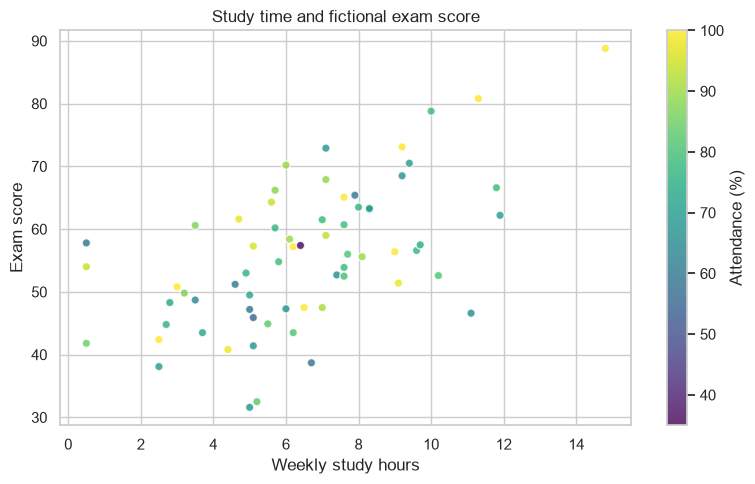

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
scatter = ax.scatter(
  students["weekly_study_hours"],
  students["exam_score"],
  c=students["attendance_percent"],
  cmap="viridis",
  alpha=0.8,
  edgecolor="white",
)
ax.set(title="Study time and fictional exam score", xlabel="Weekly study hours", ylabel="Exam score")
fig.colorbar(scatter, ax=ax, label="Attendance (%)")
fig.tight_layout()
plt.show()

### Bar plots: compare aggregated categories

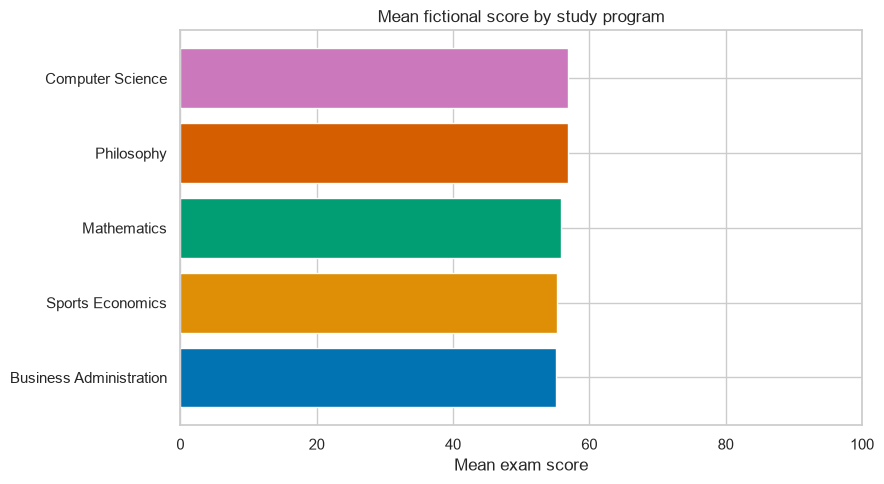

In [6]:
program_scores = (
  students.groupby("study_program")["exam_score"]
  .mean()
  .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(program_scores.index, program_scores.values, color=sns.color_palette("colorblind", len(program_scores)))
ax.set(title="Mean fictional score by study program", xlabel="Mean exam score", ylabel="")
ax.set_xlim(0, 100)
fig.tight_layout()
plt.show()

Starting a bar chart far above zero can visually exaggerate small differences. For point estimates with uncertainty, a dot plot may communicate more honestly.

### Histograms and box plots: distributions

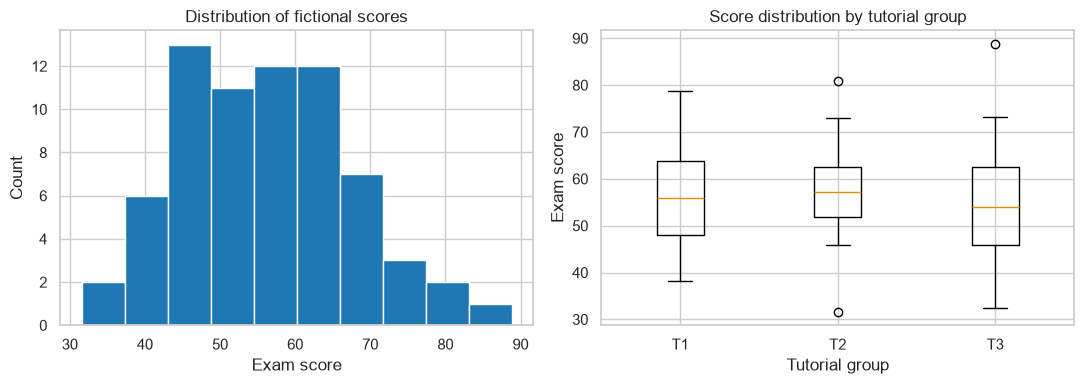

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(students["exam_score"], bins=10, color="tab:blue", edgecolor="white")
axes[0].set(title="Distribution of fictional scores", xlabel="Exam score", ylabel="Count")

program_order = sorted(students["tutorial_group"].unique())
box_values = [students.loc[students["tutorial_group"] == group, "exam_score"] for group in program_order]
axes[1].boxplot(box_values)
axes[1].set_xticks(range(1, len(program_order) + 1), program_order)
axes[1].set(title="Score distribution by tutorial group", xlabel="Tutorial group", ylabel="Exam score")

fig.tight_layout()
plt.show()

### Solution: choose a distribution

Change `chosen_column` to another numeric column and adjust the title and x-axis label.

**Explanation:** Changing the selected column is enough because the plotting code uses the same variable for the data, title, and x-axis label.

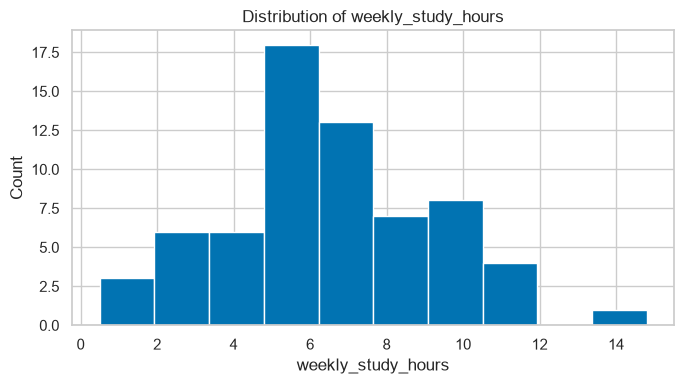

In [8]:
### --- Start Solution --- ###
chosen_column = "weekly_study_hours"
### --- End Solution --- ###

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(students[chosen_column].dropna(), bins=10, edgecolor="white")
ax.set(title=f"Distribution of {chosen_column}", xlabel=chosen_column, ylabel="Count")
fig.tight_layout()
plt.show()

## 4. Seaborn for statistical graphics

Seaborn works with tidy DataFrames and handles grouping, legends, and statistical summaries conveniently. It still creates Matplotlib figures and axes, so both libraries work together.

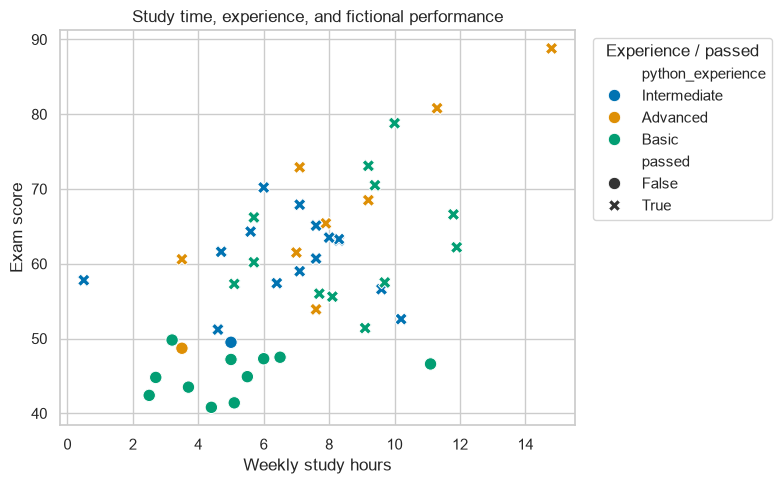

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
  data=students,
  x="weekly_study_hours",
  y="exam_score",
  hue="python_experience",
  style="passed",
  s=80,
  ax=ax,
)
ax.set(title="Study time, experience, and fictional performance", xlabel="Weekly study hours", ylabel="Exam score")
ax.legend(title="Experience / passed", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

### Categorical comparisons

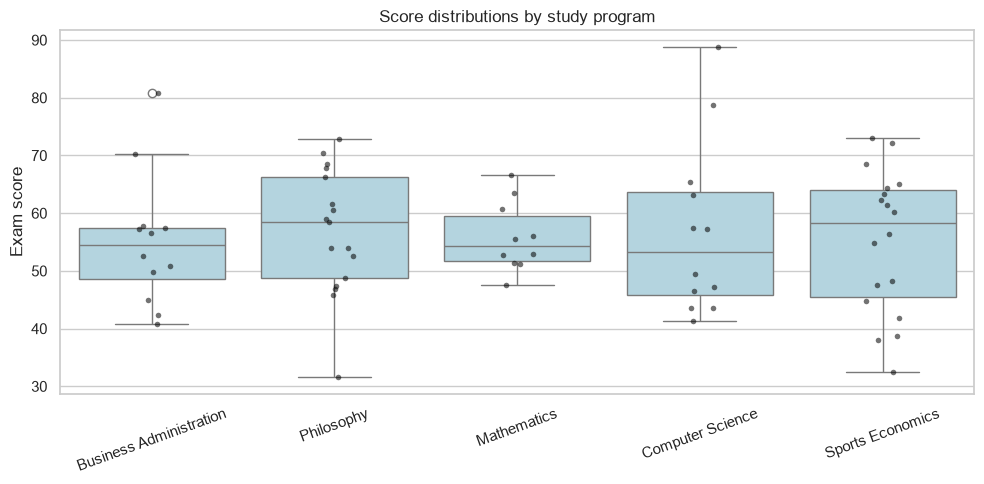

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=students, x="study_program", y="exam_score", color="lightblue", ax=ax)
sns.stripplot(data=students, x="study_program", y="exam_score", color="black", alpha=0.55, size=4, ax=ax)
ax.set(title="Score distributions by study program", xlabel="", ylabel="Exam score")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()

### Distribution plots

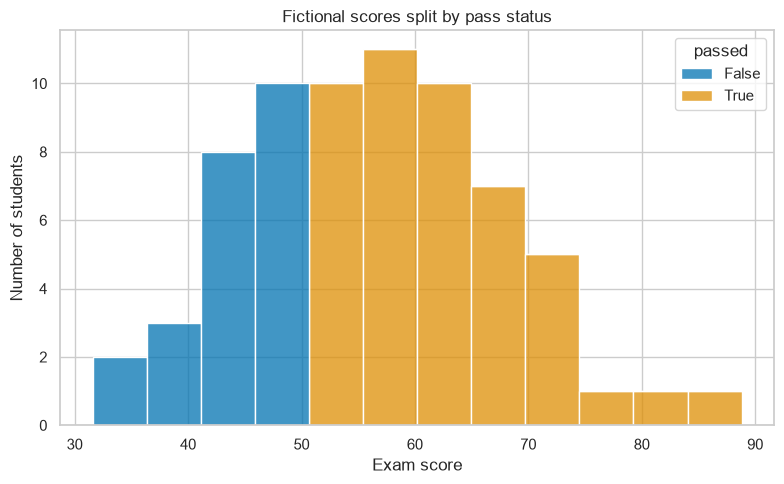

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(
  data=students,
  x="exam_score",
  hue="passed",
  bins=12,
  multiple="stack",
  ax=ax,
)
ax.set(title="Fictional scores split by pass status", xlabel="Exam score", ylabel="Number of students")
fig.tight_layout()
plt.show()

### Solution: Seaborn encoding

Change the hue to `tutorial_group` and choose a different marker size. The unedited cell still produces a valid plot.

**Explanation:** Mapping `tutorial_group` to `hue` assigns a color to each group. Increasing `s` makes the points easier to distinguish without changing the underlying values.

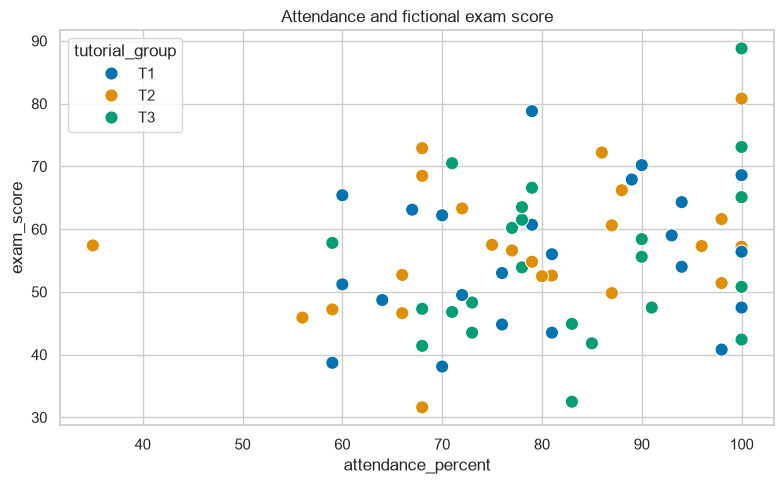

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))

### --- Start Solution --- ###
sns.scatterplot(
  data=students,
  x="attendance_percent",
  y="exam_score",
  hue="tutorial_group",
  s=90,
  ax=ax,
)
### --- End Solution --- ###

ax.set(title="Attendance and fictional exam score")
fig.tight_layout()
plt.show()

## 5. Multiple panels for exploratory analysis

Subplots place related views together. Share scales when comparison matters, and do not fill every empty corner merely because Matplotlib offered another axis.

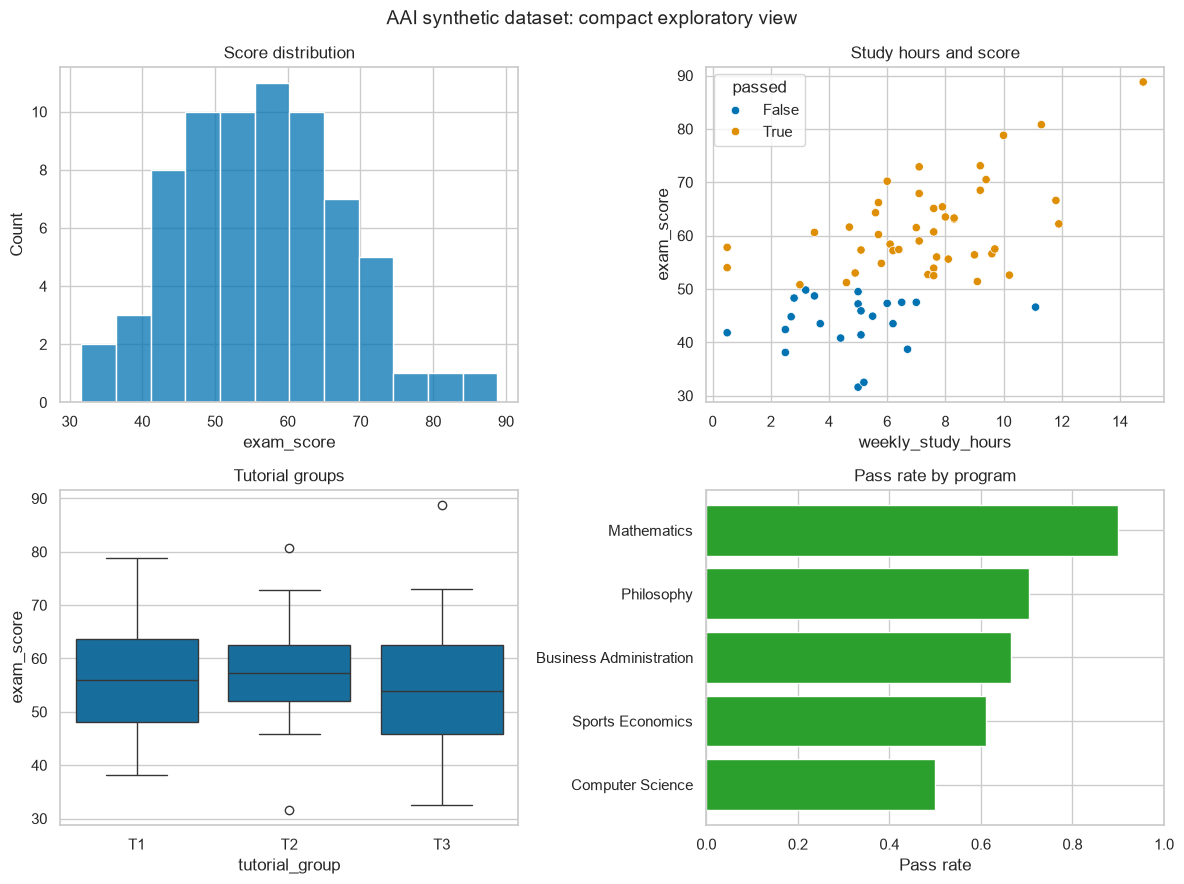

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.histplot(data=students, x="exam_score", bins=12, ax=axes[0, 0])
axes[0, 0].set_title("Score distribution")

sns.scatterplot(data=students, x="weekly_study_hours", y="exam_score", hue="passed", ax=axes[0, 1])
axes[0, 1].set_title("Study hours and score")

sns.boxplot(data=students, x="tutorial_group", y="exam_score", ax=axes[1, 0])
axes[1, 0].set_title("Tutorial groups")

pass_rate = students.groupby("study_program")["passed"].mean().sort_values()
axes[1, 1].barh(pass_rate.index, pass_rate.values, color="tab:green")
axes[1, 1].set(title="Pass rate by program", xlabel="Pass rate", xlim=(0, 1))

fig.suptitle("AAI synthetic dataset: compact exploratory view", fontsize=14)
fig.tight_layout()
plt.show()

## 6. Correlation heatmap

Correlation measures linear association. It does not prove causation, and a colorful square is not a substitute for understanding how the data was generated.

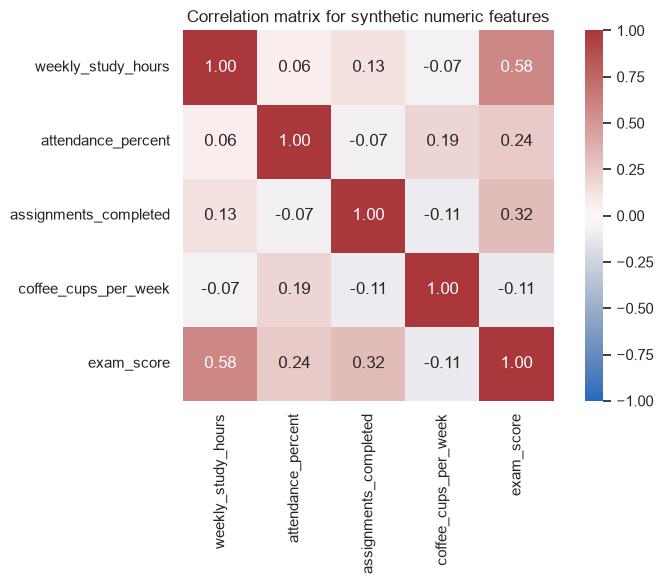

In [14]:
numeric_columns = [
  "weekly_study_hours",
  "attendance_percent",
  "assignments_completed",
  "coffee_cups_per_week",
  "exam_score",
]
correlations = students[numeric_columns].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
  correlations,
  annot=True,
  fmt=".2f",
  cmap="vlag",
  center=0,
  vmin=-1,
  vmax=1,
  square=True,
  ax=ax,
)
ax.set_title("Correlation matrix for synthetic numeric features")
fig.tight_layout()
plt.show()

## 7. Readability, accessibility, and honest charts

- State the question in the title and label axes with units.
- Use readable font sizes and sufficient contrast.
- Prefer colorblind-friendly palettes and do not rely on color alone.
- Use consistent scales when panels are compared.
- Show uncertainty or raw observations when relevant.
- Avoid unnecessary 3D effects and decorative chart junk.
- Do not cherry-pick axis limits or categories to manufacture a dramatic result.
- Explain that this tutorial dataset is synthetic; patterns are teaching artifacts, not findings about real students.

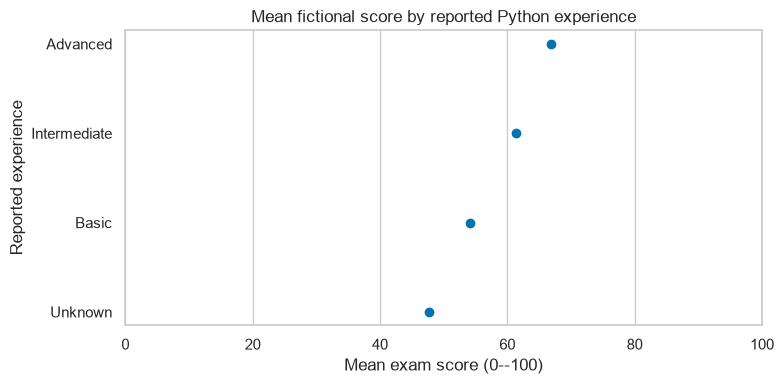

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
ordered = students.groupby("python_experience", dropna=False)["exam_score"].mean().sort_values()
ax.plot(ordered.values, ordered.index.fillna("Unknown").astype(str), marker="o", linewidth=0)
ax.set(
  title="Mean fictional score by reported Python experience",
  xlabel="Mean exam score (0--100)",
  ylabel="Reported experience",
  xlim=(0, 100),
)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## 8. Saving a figure

Use `fig.savefig()` before `plt.show()` when you need an image for a report.

```python
fig.savefig("aai_plot.png", dpi=200, bbox_inches="tight")
fig.savefig("aai_plot.svg", bbox_inches="tight")
```

PNG is convenient for raster output. SVG or PDF preserves vector graphics for many publication workflows.

## Takeaway

A good plotting workflow is:

1. Define the question and variable types.
2. Choose the simplest suitable plot.
3. Build with `fig, ax = plt.subplots()`.
4. Label the result and check scales, color, and uncertainty.
5. Interpret the pattern without claiming more than the data supports.

References: [Matplotlib tutorials](https://matplotlib.org/stable/tutorials/index.html) and [Seaborn tutorial](https://seaborn.pydata.org/tutorial.html).